# DataCo Smart Supply Chain – EDA, KPIs and RFM segmentation

Dataset: Constante, Silva & Pereira (2019), *DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS*, Mendeley Data, V5, doi:10.17632/8gx2fvg2k6.5 (CC BY 4.0).  
Place `DataCoSupplyChainDataset.csv` in `../data/` before running (see `data/README.md`).

**Note:** the raw file has 180,519 rows, but each row is an *order item*. There are 65,752 distinct orders and 20,652 customers. Counts labelled `Total_Orders` below are item counts.

In [ ]:
# Run from the notebooks/ folder. Download DataCoSupplyChainDataset.csv into ../data/ (see data/README.md)
import os
os.makedirs('../outputs', exist_ok=True)

In [ ]:
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Cấu hình hệ thống
warnings.filterwarnings("ignore")
%matplotlib inline
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
plt.style.use('seaborn-v0_8-whitegrid')

In [ ]:
# Font: matplotlib's default DejaVu Sans supports Vietnamese labels
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

1. Đọc dữ liệu và kiểm tra dữ liệu thiếu

In [ ]:
# Đọc dữ liệu
df = pd.read_csv("../data/DataCoSupplyChainDataset.csv", encoding="latin-1")
print(f"Kích thước dữ liệu gốc: {df.shape[0]:,} dòng, {df.shape[1]} cột.")

Kích thước dữ liệu gốc: 180,519 dòng, 53 cột.


In [ ]:
# Kiểm tra dữ liệu thiếu
null_summary = df.isnull().sum()
print("Các cột có dữ liệu thiếu:")
print(null_summary[null_summary > 0])


Các cột có dữ liệu thiếu (Null > 0):
Customer Lname              8
Customer Zipcode            3
Order Zipcode          155679
Product Description    180519
dtype: int64


2. Làm sạch dữ liệu và xử lý ngoại lệ

In [ ]:
# Chuẩn hóa thời gian
df['Order Date'] = pd.to_datetime(df['order date (DateOrders)'])
df['Shipping Date'] = pd.to_datetime(df['shipping date (DateOrders)'])

In [ ]:
# Loại bỏ cột dư thừa
cols_to_drop = [
    "Customer Email",
    "Customer Password",
    "Product Image",
    "Order Zipcode",
    "Product Description",
    "Customer Lname",
    "Customer Fname",
    "Order Date (DateOrders)",
    "shipping date (DateOrders)",
]
df_clean = df.drop(columns=cols_to_drop, errors="ignore")

In [ ]:
# Xử lý missing values
df_clean["Customer State"] = df_clean["Customer State"].fillna("Unknown/Other")
initial_rows = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Đã loại bỏ {initial_rows - len(df_clean):,} dòng trùng lặp.")

-> Đã loại bỏ 0 dòng trùng lặp.


In [ ]:
# Xử lý ngoại lệ (dùng hàm winsorizing)
def cap_outliers_iqr(dataframe, column):
    Q1 = dataframe[column].quantile(0.25)
    Q3 = dataframe[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = dataframe[
        (dataframe[column] < lower) | (dataframe[column] > upper)
    ].shape[0]
    print(
        f"+ Cột '{column}': Phát hiện {outliers:,} ngoại lệ, giới hạn về [{lower:.2f}, {upper:.2f}]."
    )

    df_capped = dataframe.copy()
    df_capped[column] = np.where(
        df_capped[column] < lower,
        lower,
        np.where(df_capped[column] > upper, upper, df_capped[column]),
    )
    return df_capped


print("Xử lý ngoại lệ cho doanh thu và lợi nhuận:")
df_clean = cap_outliers_iqr(df_clean, "Sales per customer")
df_clean = cap_outliers_iqr(df_clean, "Benefit per order")


Xử lý ngoại lệ cho Doanh thu & Lợi nhuận:
+ Cột 'Sales per customer': Phát hiện 1,943 ngoại lệ -> Giới hạn về [-110.15, 461.93].
+ Cột 'Benefit per order': Phát hiện 18,942 ngoại lệ -> Giới hạn về [-79.70, 151.50].


3. Thống kê mô tả tính toán các chỉ số KPI

In [1]:
# Bảng thống kê mô tả
target_cols = [
    "Days for shipping (real)",
    "Sales per customer",
    "Benefit per order",
    "Order Item Discount Rate",
    "Product Price",
]


def get_stats(data, columns):
    stats = {}
    for col in columns:
        s = data[col].dropna()
        m = s.mean()
        stats[col] = {
            "Mean": round(m, 2),
            "Median (P50/Q2)": round(s.median(), 2),
            "Mode": round(s.mode()[0], 2),
            "Std Dev": round(s.std(), 2),
            "CV (%)": round((s.std() / m) * 100 if m != 0 else 0, 2),
            "P25 (Q1)": round(s.quantile(0.25), 2),
            "P75 (Q3)": round(s.quantile(0.75), 2),
        }
    return pd.DataFrame(stats).T


print("BẢNG ĐẶC TẢ THỐNG KÊ (POST-CLEANING):")
display(get_stats(df_clean, target_cols))

# TÍNH TOÁN KPI VẬN HÀNH / TÀI CHÍNH
# 1. Số ngày lệch so với kế hoạch (>0 là giao trễ, <0 là giao sớm)
df_clean["Delay_Days"] = (
    df_clean["Days for shipping (real)"] - df_clean["Days for shipment (scheduled)"]
)

# 2. Tỷ suất lợi nhuận (%)
df_clean["Profit_Margin_%"] = np.where(
    df_clean["Sales per customer"] > 0,
    (df_clean["Benefit per order"] / df_clean["Sales per customer"]) * 100,
    0,
)

# 3. KPI theo Khu vực (Region)
region_kpi = (
    df_clean.groupby("Order Region")
    .agg(
        Total_Orders=("Order Id", "count"),
        Total_Sales=("Sales per customer", "sum"),
        Total_Profit=("Benefit per order", "sum"),
        Late_Delivery_Rate=("Late_delivery_risk", lambda x: (x.mean()) * 100),
        Avg_Delay_Days=("Delay_Days", "mean"),
    )
    .reset_index()
    .sort_values(by="Total_Sales", ascending=False)
)

# 4. KPI theo Phương thức thanh toán (Payment Type)
payment_kpi = (
    df_clean.groupby("Type")
    .agg(
        Order_Count=("Order Id", "count"),
        Late_Rate=("Late_delivery_risk", lambda x: (x.mean()) * 100),
        Avg_Profit=("Benefit per order", "mean"),
        Cancel_Count=(
            "Delivery Status",
            lambda x: (x == "Shipping canceled").sum(),
        ),
    )
    .reset_index()
)
print("--------------------------------------------------------------------------------------------------------")
print("Top 5 Khu vực có doanh thu lớn nhất và chỉ số vận hành:")
print(region_kpi.head(5).round(2))
print("--------------------------------------------------------------------------------------------------------")
print("Các phương thức thanh toán và chỉ số vận hành: ")
print(payment_kpi.head(4).round(2))

BẢNG ĐẶC TẢ THỐNG KÊ (POST-CLEANING):


NameError: name 'df_clean' is not defined

4. Phân loại khách hàng theo mô hình RFM và trực quan hóa dữ liệu

PHÂN BỔ TRỌNG SỐ KHÁCH HÀNG RFM:


                    Customer_Group  Customer_Count  Avg_Recency  Avg_Frequency  Revenue_Share_%
0     At Risk (VIP nguy cơ rời bỏ)            4103        469.9            4.4             30.2
1      Champions (VIP Trung thành)            1833        140.7            5.9             18.0
2     Lost/Hibernating (Đã rời bỏ)            1055        641.4            1.6              2.2
3   Needs Attention (Cần chăm sóc)            5132        226.8            5.1             43.4
4  Potential Loyalists (Tiềm năng)            8529         63.2            1.0              6.2

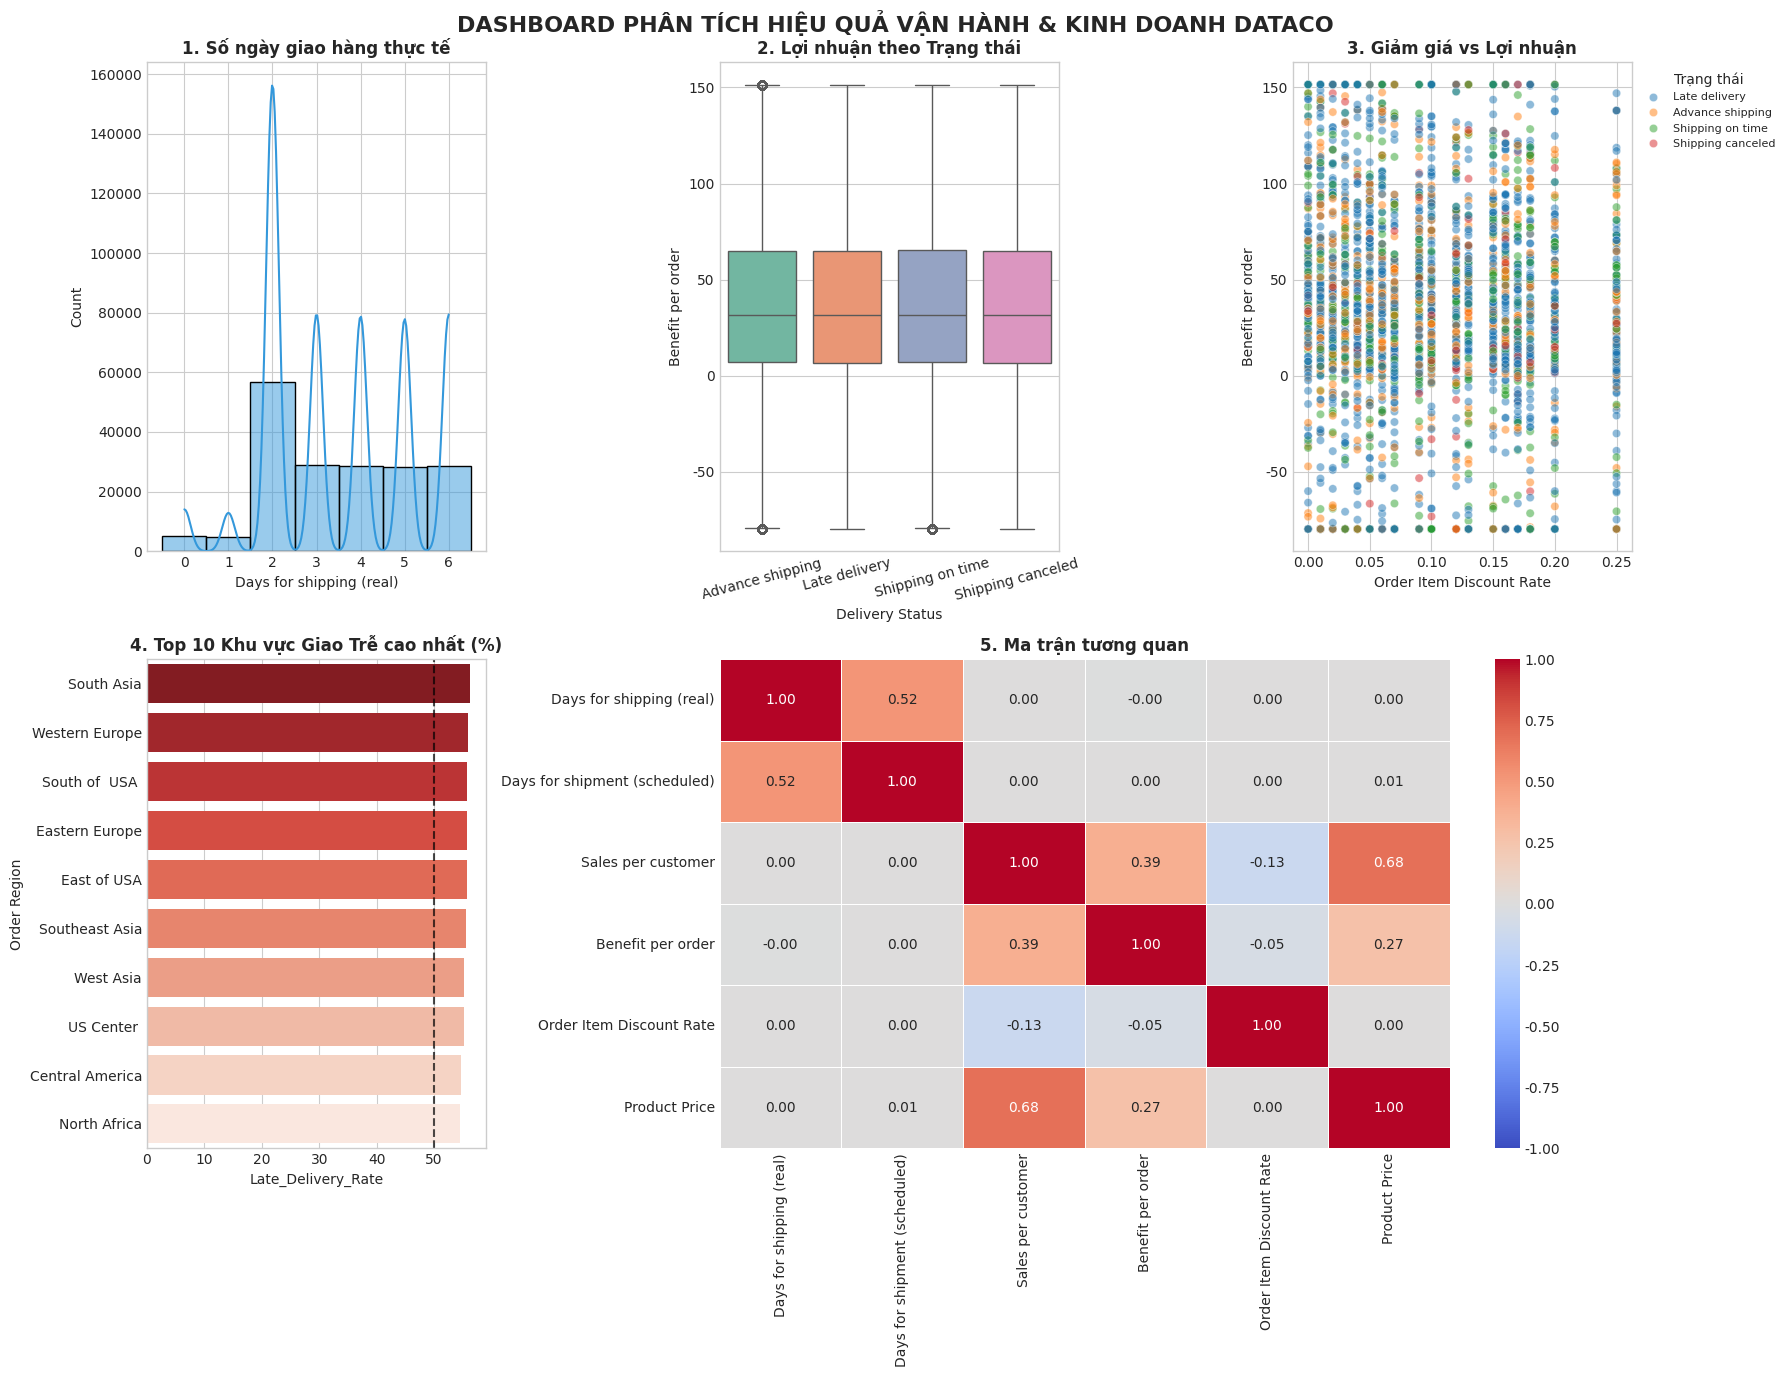

In [ ]:
# Mô hình RFM
snapshot_date = df_clean["Order Date"].max() + pd.Timedelta(days=1)
rfm = (
    df_clean.groupby("Order Customer Id")
    .agg(
        Recency=("Order Date", lambda x: (snapshot_date - x.max()).days),
        Frequency=("Order Id", "nunique"),
        Monetary=("Sales per customer", "sum"),
    )
    .reset_index()
)

rfm["R_Score"] = pd.qcut(rfm["Recency"], q=4, labels=[4, 3, 2, 1])
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"), q=4, labels=[1, 2, 3, 4]
)
rfm["M_Score"] = pd.qcut(rfm["Monetary"], q=4, labels=[1, 2, 3, 4])


def segment_rfm(row):
    r, f, m = int(row["R_Score"]), int(row["F_Score"]), int(row["M_Score"])
    if r >= 3 and f >= 3 and m >= 3:
        return "Champions (VIP Trung thành)"
    elif r >= 3 and (f <= 2 or m <= 2):
        return "Potential Loyalists (Tiềm năng)"
    elif r == 2:
        return "Needs Attention (Cần chăm sóc)"
    elif r == 1 and (f >= 3 or m >= 3):
        return "At Risk (VIP nguy cơ rời bỏ)"
    else:
        return "Lost/Hibernating (Đã rời bỏ)"


rfm["Customer_Group"] = rfm.apply(segment_rfm, axis=1)
rfm_summary = (
    rfm.groupby("Customer_Group")
    .agg(
        Customer_Count=("Order Customer Id", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Total_Revenue=("Monetary", "sum"),
    )
    .reset_index()
)
rfm_summary["Revenue_Share_%"] = round(
    (rfm_summary["Total_Revenue"] / rfm_summary["Total_Revenue"].sum()) * 100, 2
)
print("PHÂN BỔ TRỌNG SỐ KHÁCH HÀNG RFM:")
display(
    rfm_summary[
        [
            "Customer_Group",
            "Customer_Count",
            "Avg_Recency",
            "Avg_Frequency",
            "Revenue_Share_%",
        ]
    ].round(1)
)

# Vẽ Dashboard
fig = plt.figure(figsize=(18, 14))
fig.suptitle(
    "DASHBOARD PHÂN TÍCH HIỆU QUẢ VẬN HÀNH & KINH DOANH DATACO",
    fontsize=16,
    fontweight="bold",
    y=0.98,
)

# Histogram
ax1 = fig.add_subplot(2, 3, 1)
sns.histplot(
    df_clean["Days for shipping (real)"],
    bins=7,
    kde=True,
    color="#3498db",
    ax=ax1,
    discrete=True,
)
ax1.set_title("1. Số ngày giao hàng thực tế", fontweight="bold")

# Boxplot
ax2 = fig.add_subplot(2, 3, 2)
sns.boxplot(
    data=df_clean,
    x="Delivery Status",
    y="Benefit per order",
    palette="Set2",
    ax=ax2,
)
ax2.set_title("2. Lợi nhuận theo Trạng thái", fontweight="bold")
ax2.tick_params(axis="x", rotation=15)

# Scatter Plot
ax3 = fig.add_subplot(2, 3, 3)
sample_scatter = df_clean.sample(
    n=min(3000, len(df_clean)), random_state=42
)
sns.scatterplot(
    data=sample_scatter,
    x="Order Item Discount Rate",
    y="Benefit per order",
    hue="Delivery Status",
    alpha=0.5,
    palette="tab10",
    ax=ax3,
)
ax3.set_title("3. Giảm giá vs Lợi nhuận", fontweight="bold")
ax3.legend(title="Trạng thái", bbox_to_anchor=(1, 1), loc="upper left", fontsize=8)

# Bar Chart
ax4 = fig.add_subplot(2, 3, 4)
valid_regions = region_kpi[region_kpi["Total_Orders"] > 2000].sort_values(
    by="Late_Delivery_Rate", ascending=False
)
sns.barplot(
    data=valid_regions.head(10),
    x="Late_Delivery_Rate",
    y="Order Region",
    palette="Reds_r",
    ax=ax4,
)
ax4.set_title("4. Top 10 Khu vực Giao Trễ cao nhất (%)", fontweight="bold")
ax4.axvline(50, color="black", linestyle="--", alpha=0.7)

# Heatmap
ax5 = fig.add_subplot(2, 3, (5, 6))
corr_cols = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Sales per customer",
    "Benefit per order",
    "Order Item Discount Rate",
    "Product Price",
]
sns.heatmap(
    df_clean[corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=ax5,
)
ax5.set_title("5. Ma trận tương quan", fontweight="bold")

plt.tight_layout()
plt.savefig("DataCo_Dashboard.png", dpi=600)
plt.show()

5. Tải file excel

In [ ]:
# Tạo file excel và tải về máy
excel_filename = "../outputs/DataCo_Comprehensive_Supply_Chain_Project.xlsx"

with pd.ExcelWriter(excel_filename, engine="openpyxl") as writer:
    get_stats(df_clean, target_cols).to_excel(writer, sheet_name="Descriptive_Stats")
    region_kpi.to_excel(writer, sheet_name="Region_KPI", index=False)
    payment_kpi.to_excel(writer, sheet_name="Payment_KPI", index=False)
    rfm_summary.to_excel(writer, sheet_name="RFM_Summary", index=False)
    rfm[rfm["Customer_Group"].str.contains("At Risk")].to_excel(
        writer, sheet_name="Action_At_Risk_VIPs", index=False
    )
    df_clean[
        [
            "Order Id",
            "Order Date",
            "Type",
            "Order Region",
            "Department Name",
            "Sales per customer",
            "Benefit per order",
            "Profit_Margin_%",
            "Delivery Status",
            "Delay_Days",
        ]
    ].head(5000).to_excel(writer, sheet_name="Cleaned_Data_Sample", index=False)

print('Saved', excel_filename)